# 03 · Model training and evaluation

1. **Leakage demonstration:** how much the evaluation protocol alone changes the score
2. **Model comparison:** 6 classifiers × 4 ways of handling class imbalance, cross-validated on training data only
3. **Tuning:** randomised hyperparameter search for the best two models per dataset
4. **Final evaluation:** the held-out test sets are used **once**, here
5. **Save** the final models for the explainability notebook and the interface

Primary metric: **macro-F1** (treats every class equally). Accuracy is reported only for comparison with published work.

In [1]:
import sys, json, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import (RandomizedSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     train_test_split)

from src.data import BRFSS_CLASSES, load_brfss, load_diabetes_2019
from src.models import PARAM_GRIDS, build_pipeline, compare, test_report
from src.preprocess import RANDOM_STATE, prepare_brfss, prepare_diabetes_2019

PROCESSED, FIG_DIR, MODEL_DIR = ROOT / 'data/processed', ROOT / 'reports/figures', ROOT / 'models'
RESULTS_DIR = ROOT / 'reports'
sns.set_theme(style='whitegrid')

def load_split(name):
    tr, te = pd.read_csv(PROCESSED / f'{name}_train.csv'), pd.read_csv(PROCESSED / f'{name}_test.csv')
    target = tr.columns[-1]
    return tr.drop(columns=target), tr[target], te.drop(columns=target), te[target]

SPLITS = {name: load_split(name) for name in ['brfss3', 'brfss_bin', 'd19', 'd19_nomed']}
CLASS_NAMES = {'brfss3': BRFSS_CLASSES, 'brfss_bin': {0: 'No diabetes', 1: 'Diabetes'},
               'd19': {0: 'No diabetes', 1: 'Diabetes'}, 'd19_nomed': {0: 'No diabetes', 1: 'Diabetes'}}
{k: (len(v[0]), len(v[2])) for k, v in SPLITS.items()}

{'brfss3': (202944, 50736),
 'brfss_bin': (202944, 50736),
 'd19': (242, 61),
 'd19_nomed': (242, 61)}

## 1 · Leakage demonstration

The same model (Extra Trees with default settings) is evaluated with two protocols:

- **Leaky protocol:** keep duplicates, oversample the **whole** dataset, then split 80/20. This is the order Islam et al. (2024) appear to have used, based on their Table 5.
- **Leakage-free protocol:** remove duplicates (Diabetes 2019), split first, oversample the **training data only**.

This only compares protocols; it doesn't influence model selection, and it doesn't touch the saved test sets.

In [2]:
def leaky(X, y):
    Xr, yr = RandomOverSampler(random_state=RANDOM_STATE).fit_resample(X.fillna(X.median()), y)
    Xtr, Xte, ytr, yte = train_test_split(Xr, yr, test_size=0.2, stratify=yr, random_state=RANDOM_STATE)
    return ExtraTreesClassifier(n_jobs=-1, random_state=RANDOM_STATE).fit(Xtr, ytr).predict(Xte), yte

def leakage_free(X, y):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
    pipe = build_pipeline('Extra Trees', 'random oversampling')
    pipe.set_params(model__n_estimators=100)
    return pipe.fit(Xtr, ytr).predict(Xte), yte

raw19 = load_diabetes_2019()
cases = {
    'Diabetes 2019': (prepare_diabetes_2019(raw19, drop_duplicates=False), prepare_diabetes_2019(raw19)),
    'BRFSS 2015 (3-class)': (prepare_brfss(load_brfss()), prepare_brfss(load_brfss())),
}
rows = []
for name, (leaky_data, clean_data) in cases.items():
    for protocol, fn, data in (('Leaky (oversample, then split)', leaky, leaky_data),
                               ('Leakage-free (this project)', leakage_free, clean_data)):
        pred, truth = fn(*data)
        rows.append({'Dataset': name, 'Protocol': protocol, 'Accuracy': accuracy_score(truth, pred),
                     'Macro-F1': f1_score(truth, pred, average='macro')})
leak = pd.DataFrame(rows)
leak.round(3)

,Dataset,Protocol,Accuracy,Macro-F1
0,Diabetes 2019,"Leaky (oversample, then split)",0.953,0.953
1,Diabetes 2019,Leakage-free (this project),0.820,0.780
2,BRFSS 2015 (3-class),"Leaky (oversample, then split)",0.973,0.973
3,BRFSS 2015 (3-class),Leakage-free (this project),0.830,0.389


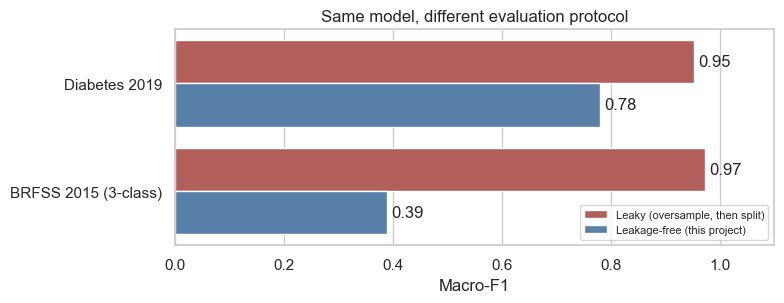

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.2))
sns.barplot(data=leak, y='Dataset', x='Macro-F1', hue='Protocol', palette=['#C0504D', '#4A7FB5'], ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', padding=3)
ax.set_xlim(0, 1.1); ax.set_ylabel(''); ax.legend(loc='lower right', fontsize=8)
ax.set_title('Same model, different evaluation protocol')
plt.tight_layout(); plt.savefig(FIG_DIR / 'model_leakage_demo.png', dpi=200); plt.show()

## 2 · Model comparison (training data only)

Every combination of 6 classifiers and 4 imbalance strategies (KNN has no class weights, so 23 in total). Imputation, BMI capping, scaling and resampling are refitted inside every training fold.

- **Diabetes 2019:** 5-fold cross-validation repeated 10 times (50 fits per combination), because 242 rows is small and one split would be noisy.
- **BRFSS:** 5-fold cross-validation on a stratified sample of 30,000 training rows. KNN is too slow on the full 203,000 rows, and a sample of this size still has about 550 prediabetes cases.

In [4]:
# Results are cached in reports/; delete cv_comparison_*.csv to recompute (about 25 minutes).
def cached(name, fn):
    path = RESULTS_DIR / f'cv_comparison_{name}.csv'
    if path.exists():
        print(f'{name}: loaded cached results from {path.name}')
        return pd.read_csv(path)
    t = time.time(); res = fn(); res.to_csv(path, index=False)
    print(f'{name}: computed in {time.time() - t:.0f}s')
    return res

cv19 = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
comparison = {}
for name in ['d19', 'd19_nomed']:
    X, y, _, _ = SPLITS[name]
    comparison[name] = cached(name, lambda: compare(X, y, cv19))
comparison['d19'].head(10).round(3)

d19: loaded cached results from cv_comparison_d19.csv
d19_nomed: loaded cached results from cv_comparison_d19_nomed.csv


,model,imbalance,macro_f1,macro_f1_std,balanced_accuracy,balanced_accuracy_std,accuracy,accuracy_std,roc_auc,roc_auc_std,seconds
0,Extra Trees,none,0.763,0.053,0.759,0.054,0.808,0.043,0.779,0.081,11.3
1,Logistic Regression,class weights,0.759,0.064,0.773,0.062,0.789,0.059,0.865,0.051,0.8
2,Extra Trees,SMOTE,0.758,0.058,0.756,0.058,0.801,0.050,0.777,0.082,17.4
3,Gradient Boosting,class weights,0.758,0.060,0.768,0.061,0.791,0.054,0.856,0.048,21.2
4,Logistic Regression,SMOTE,0.757,0.066,0.772,0.068,0.788,0.059,0.856,0.053,1.7
5,Random Forest,random oversampling,0.757,0.058,0.763,0.061,0.796,0.048,0.836,0.048,14.8
6,Logistic Regression,none,0.757,0.056,0.748,0.054,0.807,0.044,0.863,0.050,0.9
7,Logistic Regression,random oversampling,0.753,0.058,0.767,0.055,0.783,0.054,0.862,0.047,1.0
8,Extra Trees,class weights,0.750,0.056,0.750,0.060,0.794,0.047,0.776,0.079,12.2
9,Random Forest,SMOTE,0.748,0.058,0.746,0.059,0.793,0.049,0.848,0.045,20.1


In [5]:
comparison['d19_nomed'].head(10).round(3)

,model,imbalance,macro_f1,macro_f1_std,balanced_accuracy,balanced_accuracy_std,accuracy,accuracy_std,roc_auc,roc_auc_std,seconds
0,Extra Trees,SMOTE,0.743,0.063,0.740,0.064,0.790,0.052,0.761,0.084,17.4
1,Logistic Regression,random oversampling,0.741,0.060,0.760,0.065,0.770,0.055,0.836,0.056,0.7
2,Logistic Regression,class weights,0.738,0.063,0.757,0.067,0.767,0.056,0.841,0.058,0.7
3,Logistic Regression,SMOTE,0.734,0.062,0.752,0.066,0.764,0.056,0.834,0.058,1.2
4,Gradient Boosting,class weights,0.726,0.061,0.737,0.061,0.762,0.057,0.830,0.054,24.9
5,Extra Trees,random oversampling,0.725,0.062,0.721,0.063,0.777,0.052,0.756,0.083,12.4
6,Extra Trees,none,0.723,0.063,0.717,0.062,0.779,0.050,0.762,0.083,12.5
7,Random Forest,random oversampling,0.721,0.070,0.723,0.071,0.766,0.060,0.812,0.059,17.2
8,Extra Trees,class weights,0.720,0.062,0.718,0.063,0.772,0.053,0.757,0.082,12.9
9,Random Forest,SMOTE,0.719,0.066,0.716,0.066,0.772,0.055,0.821,0.059,22.5


In [6]:
Xb, yb, _, _ = SPLITS['brfss3']
Xs, _, ys, _ = train_test_split(Xb, yb, train_size=30_000, stratify=yb, random_state=RANDOM_STATE)
cv_b = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
comparison['brfss3'] = cached('brfss3', lambda: compare(Xs, ys, cv_b))
comparison['brfss3'].head(10).round(3)

brfss3: loaded cached results from cv_comparison_brfss3.csv


,model,imbalance,macro_f1,macro_f1_std,balanced_accuracy,balanced_accuracy_std,accuracy,accuracy_std,roc_auc,roc_auc_std,seconds
0,Gradient Boosting,random oversampling,0.430,0.005,0.491,0.007,0.701,0.007,0.744,0.010,64.5
1,Random Forest,random oversampling,0.425,0.005,0.416,0.004,0.837,0.004,0.743,0.010,16.3
2,Logistic Regression,random oversampling,0.422,0.007,0.504,0.021,0.643,0.006,0.766,0.011,0.5
3,Logistic Regression,class weights,0.422,0.006,0.504,0.017,0.642,0.007,0.766,0.011,0.3
4,Logistic Regression,SMOTE,0.419,0.007,0.501,0.018,0.635,0.008,0.761,0.013,1.0
5,Gradient Boosting,SMOTE,0.419,0.005,0.406,0.004,0.847,0.002,0.758,0.011,60.0
6,Gradient Boosting,class weights,0.417,0.006,0.501,0.014,0.646,0.009,0.757,0.004,9.3
7,Random Forest,SMOTE,0.413,0.004,0.401,0.003,0.844,0.002,0.745,0.007,32.9
8,Extra Trees,SMOTE,0.406,0.004,0.397,0.003,0.837,0.002,0.735,0.007,25.8
9,Gradient Boosting,none,0.406,0.006,0.393,0.004,0.852,0.003,0.777,0.007,19.4


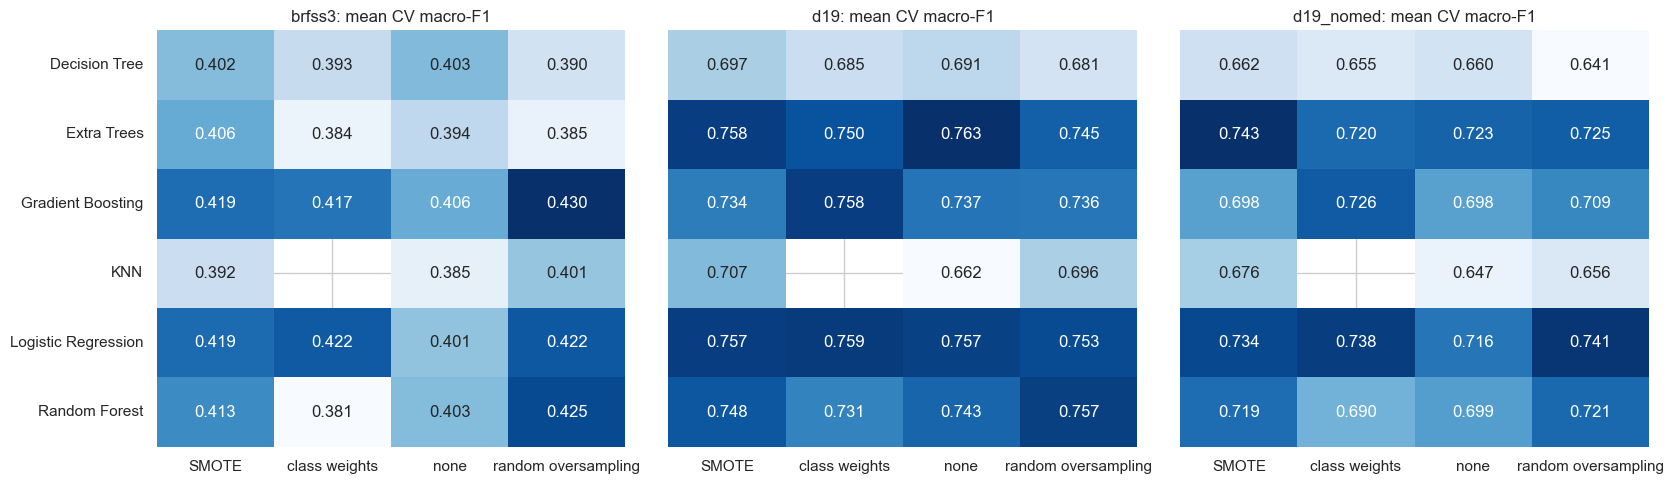

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, name in zip(axes, ['brfss3', 'd19', 'd19_nomed']):
    pivot = comparison[name].pivot(index='model', columns='imbalance', values='macro_f1')
    sns.heatmap(pivot, annot=True, fmt='.3f', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(f'{name}: mean CV macro-F1'); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.savefig(FIG_DIR / 'model_comparison_heatmap.png', dpi=200); plt.show()

## 3 · Tuning the best two models

For each dataset, the two best **different** models (each with its best imbalance strategy) are tuned with a randomised search over the grids in `src/models.py`. The search scores macro-F1 on training data only.

- Diabetes 2019: 25 settings × repeated 5-fold CV (5 repeats)
- BRFSS: 12 settings × 3-fold CV on a 60,000-row stratified sample, then refit on the full training set

In [8]:
def top_two(res):
    best = res.sort_values('macro_f1', ascending=False).drop_duplicates('model')
    return list(best.head(2)[['model', 'imbalance']].itertuples(index=False, name=None))

def tune(X, y, model, imbalance, cv, n_iter):
    search = RandomizedSearchCV(build_pipeline(model, imbalance), PARAM_GRIDS[model], n_iter=n_iter,
                                scoring='f1_macro', cv=cv, random_state=RANDOM_STATE, n_jobs=1, refit=False)
    search.fit(X, y)
    return search.best_params_, search.best_score_

TUNING_CACHE = RESULTS_DIR / 'tuning_results.csv'
if TUNING_CACHE.exists():
    tuned = pd.read_csv(TUNING_CACHE, converters={'params': json.loads})
    print('Loaded cached tuning results (delete reports/tuning_results.csv to recompute, about 30 minutes)')
else:
  tuned = []
  for name in ['d19', 'd19_nomed', 'brfss3']:
    X, y, _, _ = SPLITS[name]
    if name == 'brfss3':
        X, _, y, _ = train_test_split(X, y, train_size=60_000, stratify=y, random_state=RANDOM_STATE)
        cv, n_iter = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE), 12
    else:
        cv, n_iter = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE), 25
    for model, imbalance in top_two(comparison[name]):
        t = time.time()
        params, score = tune(X, y, model, imbalance, cv, n_iter)
        default = comparison[name].query('model == @model and imbalance == @imbalance')['macro_f1'].iloc[0]
        tuned.append({'split': name, 'model': model, 'imbalance': imbalance, 'default_cv_f1': default,
                      'tuned_cv_f1': score, 'params': params})
        print(f'{name} | {model} + {imbalance}: {default:.3f} -> {score:.3f} ({time.time() - t:.0f}s)')
  tuned = pd.DataFrame(tuned)
  tuned.assign(params=tuned['params'].map(lambda p: json.dumps({k: (v.item() if hasattr(v, 'item') else v) for k, v in p.items()}))).to_csv(TUNING_CACHE, index=False)
tuned[['split', 'model', 'imbalance', 'default_cv_f1', 'tuned_cv_f1']].round(3)

d19 | Extra Trees + none: 0.763 -> 0.769 (169s)


/Users/muktarali/Final year project/.venv/lib/python3.9/site-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 6 is smaller than n_iter=25. Running 6 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


d19 | Logistic Regression + class weights: 0.759 -> 0.769 (1s)


d19_nomed | Extra Trees + SMOTE: 0.743 -> 0.753 (320s)


/Users/muktarali/Final year project/.venv/lib/python3.9/site-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 6 is smaller than n_iter=25. Running 6 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


d19_nomed | Logistic Regression + random oversampling: 0.741 -> 0.752 (3s)


brfss3 | Gradient Boosting + random oversampling: 0.430 -> 0.435 (832s)


brfss3 | Random Forest + random oversampling: 0.425 -> 0.443 (250s)


,split,model,imbalance,default_cv_f1,tuned_cv_f1
0,d19,Extra Trees,none,0.763,0.769
1,d19,Logistic Regression,class weights,0.759,0.769
2,d19_nomed,Extra Trees,SMOTE,0.743,0.753
3,d19_nomed,Logistic Regression,random oversampling,0.741,0.752
4,brfss3,Gradient Boosting,random oversampling,0.430,0.435
5,brfss3,Random Forest,random oversampling,0.425,0.443


## 4 · Final evaluation on the held-out test sets

For each dataset, the configuration with the best tuned CV score is refitted on the **full** training set and evaluated once on the test set. The binary BRFSS version reuses the configuration chosen for 3-class BRFSS.

In [9]:
final = {}
best = tuned.sort_values('tuned_cv_f1', ascending=False).drop_duplicates('split').set_index('split')
plan = {name: best.loc[name] for name in ['d19', 'd19_nomed', 'brfss3']}
plan['brfss_bin'] = best.loc['brfss3']
overall_rows, per_class = [], {}
for name, cfg in plan.items():
    X, y, X_te, y_te = SPLITS[name]
    pipe = build_pipeline(cfg['model'], cfg['imbalance']).set_params(**cfg['params'])
    pipe.fit(X, y)
    overall, pc = test_report(pipe, X_te, y_te, CLASS_NAMES[name])
    final[name] = pipe
    per_class[name] = pc
    overall_rows.append({'split': name, 'model': cfg['model'], 'imbalance': cfg['imbalance'], **overall.to_dict()})
results = pd.DataFrame(overall_rows).set_index('split')
results.round(3)

,model,imbalance,macro_f1,balanced_accuracy,accuracy,roc_auc
split,,,,,,
d19,Extra Trees,none,0.803,0.803,0.836,0.899
d19_nomed,Extra Trees,SMOTE,0.825,0.831,0.852,0.868
brfss3,Random Forest,random oversampling,0.439,0.490,0.760,0.748
brfss_bin,Random Forest,random oversampling,0.662,0.724,0.788,0.818


In [10]:
for name, pc in per_class.items():
    print(f'\n{name}'); print(pc.round(3))


d19
             recall     f1  support
No diabetes   0.884  0.884       43
Diabetes      0.722  0.722       18

d19_nomed
             recall     f1  support
No diabetes   0.884  0.894       43
Diabetes      0.778  0.757       18

brfss3
             recall     f1  support
No diabetes   0.792  0.854    42741
Prediabetes   0.006  0.008      926
Diabetes      0.671  0.456     7069

brfss_bin
             recall     f1  support
No diabetes   0.812  0.868    43667
Diabetes      0.636  0.455     7069


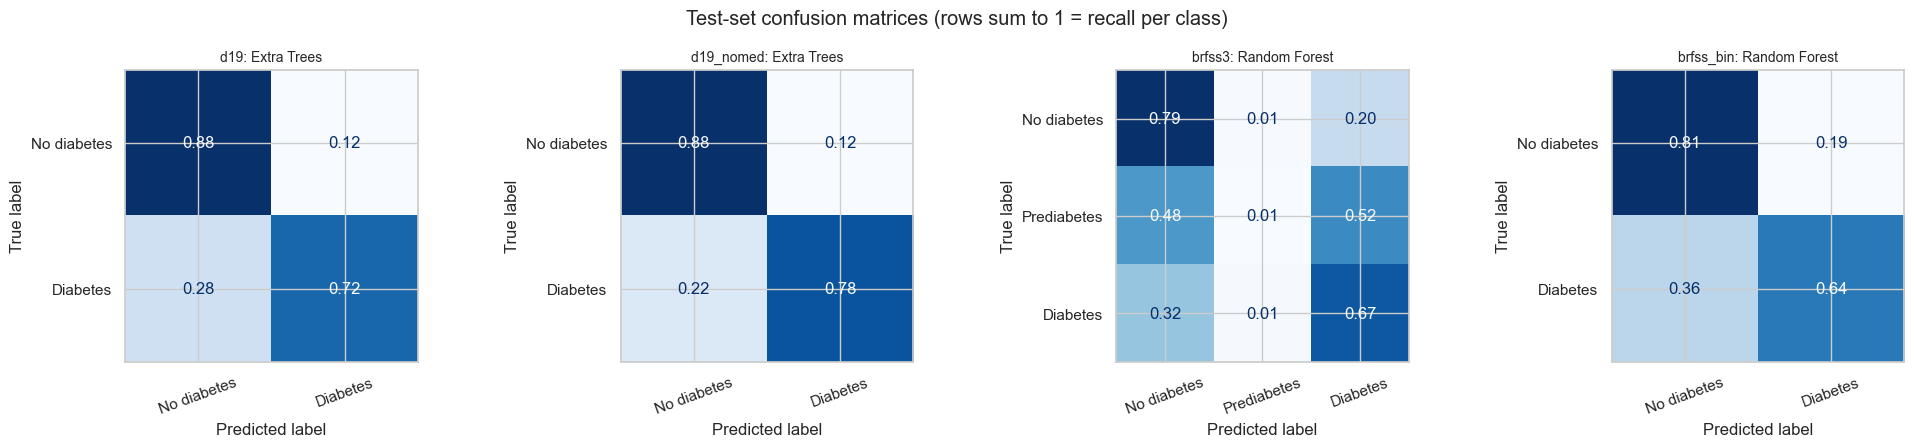

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, name in zip(axes, plan):
    _, _, X_te, y_te = SPLITS[name]
    labels = [CLASS_NAMES[name][k] for k in sorted(y_te.unique())]
    ConfusionMatrixDisplay.from_estimator(final[name], X_te, y_te, display_labels=labels, normalize='true',
                                          values_format='.2f', cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(f'{name}: {plan[name]["model"]}', fontsize=10)
    ax.tick_params(axis='x', labelrotation=20)
plt.suptitle('Test-set confusion matrices (rows sum to 1 = recall per class)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'model_confusion_matrices.png', dpi=200); plt.show()

### Comparison with published results

Accuracy is shown because that is what the papers report. Islam et al. (2024) used the leaky protocol shown in Section 1. Xie et al. (2019) used the 2014 BRFSS survey with a binary target, so they're closest to `brfss_bin`.

In [12]:
published = pd.DataFrame([
    {'Source': 'Islam et al. (2024)', 'Dataset': 'BRFSS 2015, 3-class', 'Accuracy': 0.9723},
    {'Source': 'Islam et al. (2024)', 'Dataset': 'Diabetes 2019', 'Accuracy': 0.9745},
    {'Source': 'Xie et al. (2019)', 'Dataset': 'BRFSS 2014, binary', 'Accuracy': 0.824},
    {'Source': 'This project', 'Dataset': 'BRFSS 2015, 3-class', 'Accuracy': results.loc['brfss3', 'accuracy']},
    {'Source': 'This project', 'Dataset': 'BRFSS 2015, binary', 'Accuracy': results.loc['brfss_bin', 'accuracy']},
    {'Source': 'This project', 'Dataset': 'Diabetes 2019', 'Accuracy': results.loc['d19', 'accuracy']},
    {'Source': 'This project', 'Dataset': 'Diabetes 2019, no RegularMedicine', 'Accuracy': results.loc['d19_nomed', 'accuracy']},
])
published.round(3)

,Source,Dataset,Accuracy
0,Islam et al. (2024),"BRFSS 2015, 3-class",0.972
1,Islam et al. (2024),Diabetes 2019,0.974
2,Xie et al. (2019),"BRFSS 2014, binary",0.824
3,This project,"BRFSS 2015, 3-class",0.760
4,This project,"BRFSS 2015, binary",0.788
5,This project,Diabetes 2019,0.836
6,This project,"Diabetes 2019, no RegularMedicine",0.852


## 5 · Save models and results

In [13]:
for name, pipe in final.items():
    joblib.dump(pipe, MODEL_DIR / f'{name}.joblib', compress=3)
summary = {
    name: {'model': plan[name]['model'], 'imbalance': plan[name]['imbalance'],
           'params': {k: (v if not hasattr(v, 'item') else v.item()) for k, v in plan[name]['params'].items()},
           'test': results.loc[name, ['macro_f1', 'balanced_accuracy', 'accuracy', 'roc_auc']].astype(float).round(4).to_dict(),
           'size_mb': round((MODEL_DIR / f'{name}.joblib').stat().st_size / 1e6, 1)}
    for name in plan
}
(RESULTS_DIR / 'final_models.json').write_text(json.dumps(summary, indent=2))
leak.to_csv(RESULTS_DIR / 'leakage_demo.csv', index=False)
print(json.dumps(summary, indent=2))

{
  "d19": {
    "model": "Extra Trees",
    "imbalance": "none",
    "params": {
      "model__n_estimators": 400,
      "model__min_samples_leaf": 5,
      "model__max_features": "sqrt",
      "model__max_depth": 16
    },
    "test": {
      "macro_f1": 0.803,
      "balanced_accuracy": 0.803,
      "accuracy": 0.8361,
      "roc_auc": 0.8992
    },
    "size_mb": 0.3
  },
  "d19_nomed": {
    "model": "Extra Trees",
    "imbalance": "SMOTE",
    "params": {
      "model__n_estimators": 400,
      "model__min_samples_leaf": 10,
      "model__max_features": "sqrt",
      "model__max_depth": 24
    },
    "test": {
      "macro_f1": 0.8254,
      "balanced_accuracy": 0.8307,
      "accuracy": 0.8525,
      "roc_auc": 0.8682
    },
    "size_mb": 0.3
  },
  "brfss3": {
    "model": "Random Forest",
    "imbalance": "random oversampling",
    "params": {
      "model__n_estimators": 200,
      "model__min_samples_leaf": 5,
      "model__max_features": "sqrt",
      "model__max_depth": n

## Findings

**1. The evaluation protocol alone explains most of the published 97%.** With the same model (Extra Trees, default settings), oversampling the whole dataset before splitting gives a macro-F1 of **0.95** on Diabetes 2019 and **0.97** on BRFSS. The leakage-free protocol gives **0.78** and **0.39**. The model doesn't change; only the order of the steps does (`model_leakage_demo.png`).

**2. Realistic performance (held-out test sets, used once):**

| Split | Model | Macro-F1 | Accuracy | ROC-AUC |
|---|---|---|---|---|
| Diabetes 2019 | Extra Trees | 0.80 | 0.84 | 0.90 |
| Diabetes 2019, no RegularMedicine | Extra Trees + SMOTE | 0.83 | 0.85 | 0.87 |
| BRFSS 3-class | Random Forest + oversampling | 0.44 | 0.76 | 0.75 |
| BRFSS binary | Random Forest + oversampling | 0.66 | 0.79 | 0.82 |

BRFSS binary (ROC-AUC 0.82) is in line with Xie et al. (2019), who reported 0.79 on BRFSS 2014.

**3. Prediabetes can't be predicted from these survey answers.** Recall is 0.6%: prediabetes cases are split between "no diabetes" and "diabetes". This matches the EDA, where prediabetes respondents looked like a mix of both groups. The binary BRFSS model is the realistic choice for any BRFSS-based tool.

**4. Dropping RegularMedicine costs little.** In cross-validation, macro-F1 falls from 0.769 to 0.753. On the test set the version without it actually scores higher, but with only 61 test rows (18 with diabetes), one or two people change these numbers. The cross-validation standard deviation is about ±0.06, so the two versions can't be told apart.

**5. Simple models are competitive.** On Diabetes 2019, tuned Logistic Regression ties with Extra Trees in cross-validation (0.769 vs 0.769) and has a better ROC-AUC (0.865 vs 0.779 untuned). Its probabilities are also more reliable, which matters for an interface that shows a risk percentage.

**6. Practical limits.** The BRFSS Random Forest files are 123–165 MB even when compressed. Gradient Boosting scored almost the same in cross-validation (0.435 vs 0.443) and would be a fraction of the size.

**7. Imbalance handling.** Oversampling or class weights helped every model on BRFSS. The best strategy varied by model, and no single method was best everywhere.
